# What kinds of items are most easily repaired?

**Author:** Philip

We measure "easily repaired" two ways: the share of items fully repaired, and the average repairability rating (1 = difficult, 10 = easy).

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

repairs = pd.read_csv("repairs.csv", parse_dates=["repair_date"])
print(repairs.shape)
repairs["repaired"].value_counts(dropna=False)

(178749, 11)


repaired
yes     112775
no       43112
half     22859
NaN          2
ja           1
Name: count, dtype: int64

In [2]:
# "Fully repaired" = answered Yes (Half and No count as not fully repaired)
repairs["fully_repaired"] = repairs["repaired"].fillna("").str.strip().str.lower().str.startswith("y")
overall_rate = repairs["fully_repaired"].mean()
print(f"Overall: {overall_rate:.1%} of {len(repairs):,} cases fully repaired")

Overall: 63.1% of 178,749 cases fully repaired


## By product category

Only categories with at least 200 cases are shown.

In [3]:
by_category = (
    repairs.dropna(subset=["category"])
    .groupby("category")
    .agg(n=("repair_id", "size"),
         repair_rate=("fully_repaired", "mean"),
         mean_repairability=("repairability", "mean"))
    .query("n >= 200")
    .sort_values("repair_rate", ascending=False)
)
by_category.round(2)

,n,repair_rate,mean_repairability
category,,,
Textile,24412,0.92,7.55
Tools non-electric,4178,0.90,8.04
Jewelry,2852,0.83,7.48
Bicycles,6252,0.82,6.95
Household appliances non-electric,5593,0.81,7.53
Furniture,2120,0.75,6.79
Toys non-electric,2015,0.74,6.75
Other,10435,0.67,6.81
Clocks / alarm clocks,7016,0.62,6.62


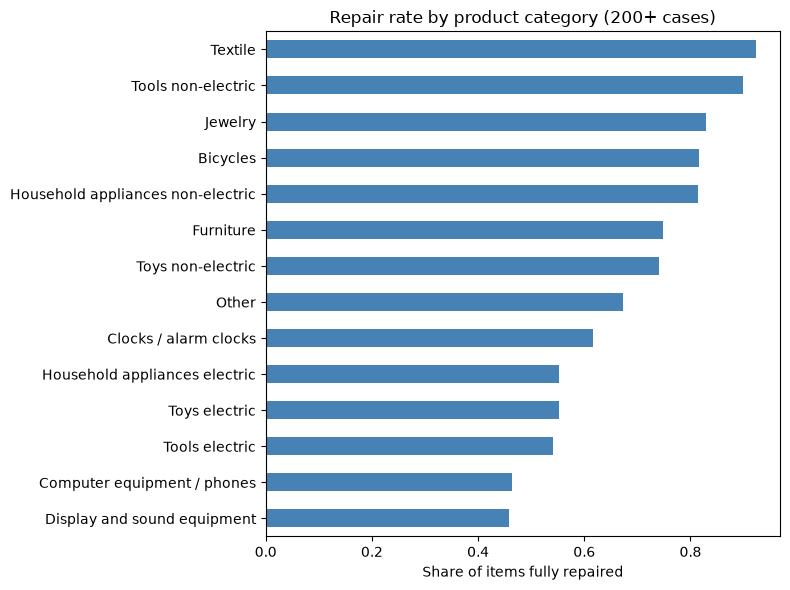

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
by_category["repair_rate"].sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Share of items fully repaired")
ax.set_ylabel("")
ax.set_title("Repair rate by product category (200+ cases)")
plt.tight_layout()
plt.savefig("figures/philip_repair_rate_by_category.png", dpi=150)
plt.show()

## By kind of product

Only products with at least 100 cases. Most easily repaired first:

In [5]:
by_kind = (
    repairs.dropna(subset=["kind_of_product"])
    .groupby("kind_of_product")
    .agg(n=("repair_id", "size"),
         repair_rate=("fully_repaired", "mean"),
         mean_repairability=("repairability", "mean"))
    .query("n >= 100")
    .sort_values("repair_rate", ascending=False)
)
by_kind.head(10).round(2)

,n,repair_rate,mean_repairability
kind_of_product,,,
Chisel,119,0.99,8.15
Pyjamas,175,0.98,8.10
Towel,127,0.98,8.38
Knife / knives / scissors,2915,0.98,8.41
Leggings,108,0.97,7.53
Sock,234,0.97,6.66
T-shirt / Shirt,718,0.96,7.60
Trousers / pants,6769,0.96,7.73
Shirt (dress shirt),446,0.96,7.78


Hardest to repair:

In [6]:
by_kind.tail(10).round(2)

,n,repair_rate,mean_repairability
kind_of_product,,,
Steam appliance (for textiles),174,0.34,5.36
Electric blanket / Electric throw,301,0.33,5.47
Sound bar,155,0.33,5.65
Induction hob,151,0.32,5.90
Video player / recorder,551,0.32,5.48
Milk frother,667,0.30,5.38
Electric toothbrush,269,0.30,4.93
E-reader / E-book reader,259,0.30,5.33
Television,1293,0.30,5.14


## Takeaway

In [7]:
print(f"Most easily repaired category: {by_category.index[0]} ({by_category['repair_rate'].iloc[0]:.0%} fully repaired).")
print(f"Hardest category: {by_category.index[-1]} ({by_category['repair_rate'].iloc[-1]:.0%}).")
print(f"Most easily repaired product: {by_kind.index[0]} ({by_kind['repair_rate'].iloc[0]:.0%}).")

summary = {
    "n_cases": int(len(repairs)),
    "overall_rate": float(overall_rate),
    "top_categories": [[c, float(r)] for c, r in by_category["repair_rate"].head(3).items()],
    "bottom_categories": [[c, float(r)] for c, r in by_category["repair_rate"].tail(3).items()],
    "top_products": [[c, float(r)] for c, r in by_kind["repair_rate"].head(3).items()],
}
with open("figures/philip_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

Most easily repaired category: Textile (92% fully repaired).
Hardest category: Display and sound equipment (46%).
Most easily repaired product: Chisel (99%).
